# Read AskReddit post scores — January 2025

Inspect the **archived score of individual posts**, including their IDs, titles, and UTC posting times. The default source is the complete January extract; choose the cleaned January pilot explicitly if needed.

This notebook reads local Parquet with DuckDB. It does not start Spark, download posts, clean data, or assign popularity labels. Scores are archive observations, not live scores or counts of upvotes. Missing, zero, and negative scores are preserved.

**Run:** from the repository root in WSL, install `.venv/bin/python -m pip install -e '.[notebook]'`, then open this file with `.venv/bin/python -m jupyterlab notebooks/01_january_2025_scores.ipynb`. In VS Code, select the repository's `.venv/bin/python` kernel. Run cells from top to bottom.

Change `DATASET` below and rerun all cells to switch sources. Edit the browsing controls to inspect different posts; only rerun the browsing cell for those changes.

In [2]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Works when the kernel starts in either the repository root or notebooks/.
ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "configs/project.toml").is_file()
     and (path / "src/askreddit").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the askreddit-popularity repository.")

pd.set_option("display.max_colwidth", None)
print(f"Repository: {ROOT}")
print(f"DuckDB: {duckdb.__version__}")

Repository: /home/hoangnnh/Coding/IE212/project/askreddit-popularity
DuckDB: 1.5.4


In [3]:
DATASET = "raw"  # "raw" = all extracted posts; "cleaned" = the January cleaning pilot

if DATASET == "raw":
    source_files = [ROOT / "data/extracted/askreddit-2025-01.parquet"]
elif DATASET == "cleaned":
    source_files = sorted((ROOT / "data/samples/cleaned-2025-01").glob("*.parquet"))
else:
    raise ValueError('DATASET must be "raw" or "cleaned".')

if not source_files or any(not path.is_file() for path in source_files):
    raise FileNotFoundError(
        f"The {DATASET} January dataset is missing. See README.md for ingestion/cleaning commands."
    )

# Keep reruns independent; this is an in-memory database.
if "connection" in globals():
    connection.close()
connection = duckdb.connect(config={"threads": 2, "memory_limit": "1GB"})
connection.execute("SET TimeZone = 'UTC'")
connection.read_parquet([str(path) for path in source_files]).create_view("january_posts")

scope = connection.execute("""
    SELECT count(*) AS row_count,
           count(*) FILTER (
               WHERE created_utc IS NULL
                  OR created_utc < 1735689600 OR created_utc >= 1738368000
           ) AS outside_january_utc,
           count(*) FILTER (
               WHERE subreddit IS NULL OR lower(subreddit) <> 'askreddit'
           ) AS invalid_subreddit
    FROM january_posts
""").fetchone()
assert scope[0] > 0, "The selected dataset is empty."
assert scope[1:] == (0, 0), "The source includes rows outside January 2025 UTC or r/AskReddit."

# Load only the columns needed to read post scores, not the post bodies.
posts = connection.execute("""
    SELECT id, title, created_utc, score
    FROM january_posts
    ORDER BY created_utc, id
""").df()
posts["score"] = posts["score"].astype("Int64")  # Preserve missing scores as <NA>.
posts["posted_at_utc"] = pd.to_datetime(posts["created_utc"], unit="s", utc=True)
assert len(posts) == scope[0]

print(f"Selected source: {DATASET}")
print(f"Posts loaded: {len(posts):,}")
print(f"UTC interval: {posts['posted_at_utc'].min()} through {posts['posted_at_utc'].max()}")
print("Input files:")
for path in source_files:
    print(f"  {path.relative_to(ROOT)}")

Selected source: raw
Posts loaded: 147,226
UTC interval: 2025-01-01 00:00:07+00:00 through 2025-01-31 23:59:12+00:00
Input files:
  data/extracted/askreddit-2025-01.parquet


## Score overview

Counts refer to the selected source. The mean, percentiles, and percentage with score 1 use **non-missing scores only**. Percentiles use exact linear interpolation. A median of 1 does not mean that exactly half the posts have score 1; use the frequency table to inspect ties.

In [4]:
result = connection.execute("""
    SELECT count(*) AS post_count,
           count(DISTINCT id) AS distinct_ids,
           count(score) AS known_scores,
           count(*) - count(score) AS missing_scores,
           min(score) AS min_score,
           avg(score) AS mean_score,
           median(score) AS median_score,
           quantile_cont(score, 0.75) AS p75_score,
           quantile_cont(score, 0.95) AS p95_score,
           quantile_cont(score, 0.99) AS p99_score,
           max(score) AS max_score,
           count(*) FILTER (WHERE score = 1) AS score_eq_1_count,
           100.0 * count(*) FILTER (WHERE score = 1) / nullif(count(score), 0)
               AS score_eq_1_percent
    FROM january_posts
""")
summary = dict(zip([column[0] for column in result.description], result.fetchone()))
display(pd.DataFrame(
    [(key, f"{value:,}" if isinstance(value, int) else
      f"{value:,.3f}" if isinstance(value, float) else value)
     for key, value in summary.items()],
    columns=["metric", "value"],
))

,metric,value
0,post_count,"147,226"
1,distinct_ids,"147,226"
2,known_scores,"147,226"
3,missing_scores,0
4,min_score,0
5,mean_score,12.568
6,median_score,1.000
7,p75_score,2.000
8,p95_score,5.000
9,p99_score,72.000


## Read individual posts

The table shows the original ID, score, UTC posting time, and full title. `posts` contains all loaded rows; the displayed table is paginated.

Edit the **controls cell** below:
- `MIN_SCORE = 100` shows posts with score at least 100.
- `MIN_SCORE = MAX_SCORE = 1` shows only score-1 posts.
- `TITLE_CONTAINS = "why"` searches titles case-insensitively as literal text.
- `POST_ID` selects an exact ID copied from the table.
- `SORT_BY = "created_utc"` with `ASCENDING = True` reads posts chronologically.
- Increase `PAGE` to read more results. `PAGE_SIZE` is limited to 500.
- `ONLY_MISSING_SCORE = True` shows missing scores; leave both score bounds as `None`.

Filters combine with AND. Numeric score bounds exclude missing scores. Without bounds, missing scores are included and sorted last. No filter changes the underlying dataset.

In [8]:
def browse_posts(
    min_score=None, max_score=None, title_contains="", post_id="",
    only_missing=False, sort_by="score", ascending=False, page=1, page_size=25,
):
    if page < 1 or not 1 <= page_size <= 500:
        raise ValueError("Use PAGE >= 1 and 1 <= PAGE_SIZE <= 500.")
    if sort_by not in {"score", "created_utc"}:
        raise ValueError('SORT_BY must be "score" or "created_utc".')
    if min_score is not None and max_score is not None and min_score > max_score:
        raise ValueError("MIN_SCORE cannot exceed MAX_SCORE.")

    mask = pd.Series(True, index=posts.index)
    if min_score is not None:
        mask &= posts["score"].ge(min_score).fillna(False)
    if max_score is not None:
        mask &= posts["score"].le(max_score).fillna(False)
    if title_contains:
        mask &= posts["title"].str.contains(title_contains, case=False, regex=False, na=False)
    if post_id:
        mask &= posts["id"].eq(post_id)
    if only_missing:
        mask &= posts["score"].isna()

    matching = posts.loc[mask]
    order = [sort_by] + [column for column in ["created_utc", "id"] if column != sort_by]
    ordered = matching.sort_values(
        order, ascending=[ascending] + [True] * (len(order) - 1),
        na_position="last", kind="stable",
    )
    total = len(ordered)
    page_count = (total + page_size - 1) // page_size
    start = (page - 1) * page_size
    print(f"Source: {DATASET} | Matching posts: {total:,} | Page {page} of {page_count}")
    if total and start >= total:
        print("This page is past the last result. Reduce PAGE.")
    return ordered.iloc[start:start + page_size][
        ["id", "score", "posted_at_utc", "title"]
    ].reset_index(drop=True)

In [6]:
MIN_SCORE = None
MAX_SCORE = None
TITLE_CONTAINS = ""
POST_ID = ""
ONLY_MISSING_SCORE = False
SORT_BY = "score"  # "score" or "created_utc"
ASCENDING = False
PAGE = 1
PAGE_SIZE = 25

display(browse_posts(
    min_score=MIN_SCORE, max_score=MAX_SCORE, title_contains=TITLE_CONTAINS,
    post_id=POST_ID, only_missing=ONLY_MISSING_SCORE,
    sort_by=SORT_BY, ascending=ASCENDING, page=PAGE, page_size=PAGE_SIZE,
))

Source: raw | Matching posts: 147,226 | Page 1 of 5890


,id,score,posted_at_utc,title
0,1i6rjf2,50514,2025-01-21 19:53:36+00:00,What are your thoughts of a Reddit wide ban of x links?
1,1i6160l,36543,2025-01-20 21:09:30+00:00,How do you feel about Elon Musk's salutes during the inauguration?
2,1ieqy24,23444,2025-01-31 22:14:47+00:00,What do you make of Elon Musk aides locking government workers out of computer systems at a US agency?
3,1id8bvr,22104,2025-01-29 23:44:49+00:00,What do you make of President Trump sending illegal immigrants to Guantanamo Bay?
4,1htdpiu,18779,2025-01-04 12:49:02+00:00,"For those who think the billionaire Soros is secretly controlling the government, what do you say about Elon doing the same thing in the public square?"
5,1ie2w4d,18441,2025-01-31 01:06:13+00:00,Do you know (of) someone who ruined their life in just a matter of minutes ? If so how did they do it ?
6,1i88o15,17238,2025-01-23 17:24:53+00:00,"If someone grabbed you out of your chair right now and said you have to give a one hour speech on any topic of your choice as long as it was informative and they would pay you $10,000, what would your speech be about?"
7,1hzglw3,14371,2025-01-12 06:24:34+00:00,"For those who used a computer between 1995 and 2001, what’s the computer game from that time that sticks with you the most, and why?"
8,1i690lc,13677,2025-01-21 03:07:09+00:00,Americans how are you feeling right now?
9,1iejd4p,13524,2025-01-31 16:57:07+00:00,"Today is 5 years since the U.S. declared public health emergency over COVID-19, what are your thoughts on the pandemic in retrospect?"


## Lowest scores and missing scores

This view is independent of the browsing controls above. It includes score 0 and negative scores if present; missing scores are reported separately.

In [ ]:
display(browse_posts(ascending=True, page_size=10))
print(f"Missing scores: {summary['missing_scores']:,}")
if summary["missing_scores"]:
    display(browse_posts(only_missing=True, page_size=10))

## How often does each score occur?

Each row below is an **exact score**, not a histogram bin. `share_percent` uses the number of non-missing scores as the denominator; `cumulative_percent` is the share with score less than or equal to that row's score. The display shows the first 30 distinct scores; `score_frequency` contains the full table.

In [9]:
score_frequency = connection.execute("""
    SELECT score, count(*) AS post_count
    FROM january_posts
    WHERE score IS NOT NULL
    GROUP BY score
    ORDER BY score
""").df()
known_count = int(score_frequency["post_count"].sum())
score_frequency["share_percent"] = (
    100 * score_frequency["post_count"] / known_count if known_count else float("nan")
)
score_frequency["cumulative_percent"] = score_frequency["share_percent"].cumsum()
assert known_count == summary["known_scores"]
display(score_frequency.head(30).round(3))

,score,post_count,share_percent,cumulative_percent
0,0,28646,19.457,19.457
1,1,76921,52.247,71.704
2,2,21141,14.360,86.064
3,3,9389,6.377,92.441
4,4,3456,2.347,94.788
5,5,2140,1.454,96.242
6,6,1179,0.801,97.043
7,7,645,0.438,97.481
8,8,410,0.278,97.759
9,9,228,0.155,97.914


## Score-frequency plots

The left plot shows every distinct non-missing score. Its **symmetric-log x-axis** retains zero and negative scores while making the high-score tail visible. Both plots use a **logarithmic count axis**. The right plot zooms into scores from -5 to 20; it intentionally omits other scores.

A PNG is saved under Git-ignored `artifacts/exploration/2025-01/` for sharing. The file name includes the selected source.

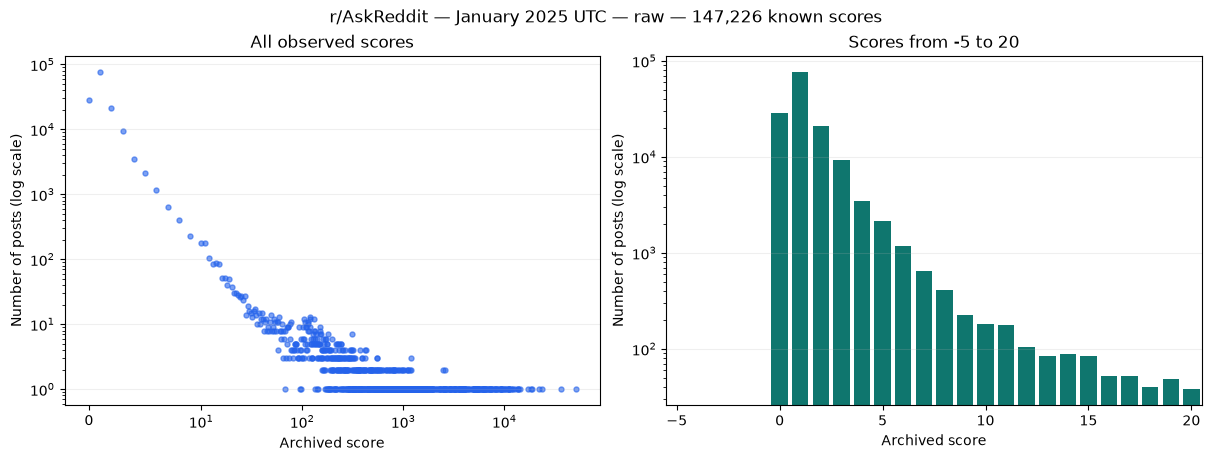

Saved figure: artifacts/exploration/2025-01/raw-score-frequency.png


In [10]:
artifact_dir = ROOT / "artifacts/exploration/2025-01"
if score_frequency.empty:
    print("There are no non-missing scores to plot.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    axes[0].scatter(
        score_frequency["score"], score_frequency["post_count"],
        s=13, alpha=0.6, color="#2563eb",
    )
    axes[0].set_xscale("symlog", linthresh=10)
    axes[0].set_title("All observed scores")
    near_zero = score_frequency[score_frequency["score"].between(-5, 20)]
    axes[1].bar(near_zero["score"], near_zero["post_count"], color="#0f766e")
    axes[1].set_xlim(-5.5, 20.5)
    axes[1].set_xticks(range(-5, 21, 5))
    axes[1].set_title("Scores from -5 to 20")
    for axis in axes:
        axis.set_yscale("log")
        axis.set_xlabel("Archived score")
        axis.set_ylabel("Number of posts (log scale)")
        axis.grid(axis="y", alpha=0.2)
    fig.suptitle(f"r/AskReddit — January 2025 UTC — {DATASET} — {known_count:,} known scores")
    artifact_dir.mkdir(parents=True, exist_ok=True)
    figure_path = artifact_dir / f"{DATASET}-score-frequency.png"
    fig.savefig(figure_path, dpi=160)
    plt.show()
    plt.close(fig)
    print(f"Saved figure: {figure_path.relative_to(ROOT)}")

## Optional: export all post scores to CSV

Set `EXPORT_CSV = True` to save every loaded post with its ID, title, original timestamp, score, and UTC posting time. This export is independent of the browsing filters and remains in chronological order. Missing scores are empty CSV fields. Rerunning this cell replaces the CSV for the selected source; the source Parquet files are read-only.

In [ ]:
EXPORT_CSV = False

if EXPORT_CSV:
    artifact_dir.mkdir(parents=True, exist_ok=True)
    csv_path = artifact_dir / f"{DATASET}-post-scores.csv"
    posts.to_csv(csv_path, index=False)
    print(f"Exported {len(posts):,} posts to {csv_path.relative_to(ROOT)}")
else:
    print("CSV export is off. Set EXPORT_CSV = True and rerun this cell to export all rows.")

## Interpretation boundaries

- The raw source includes posts that the cleaning stage may remove. The cleaned source reflects the documented title/body filters and ID deduplication.
- January observations describe this month only. They are not the final full-year analysis.
- A large mass at score 1 and ties at percentiles can affect class sizes. Do not assume that `score >= p75` contains exactly 25% of posts.
- This notebook does not define high/low labels. Any learned score threshold must later be calculated on the chronological **training** partition only.